# GIAI ĐOẠN 2: THỰC THI QUY TRÌNH KHAI PHÁ DỮ LIỆU (KDD PIPELINE)
**Dữ liệu đầu vào:** `raw_jobs_data.csv` (Dữ liệu tuyển dụng ngành Data & AI từ VietnamWorks, TopCV)

**Nội dung thực hiện:**
- **Bước 2.1:** Tiền xử lý & Làm sạch dữ liệu tuyển dụng (Data Cleaning)
  - Chuẩn hóa mức lương bằng Regex (`Luong_Min`, `Luong_Max`, `Luong_TB`, `La_Thoa_Thuan`)
  - Chuẩn hóa địa điểm, số năm kinh nghiệm & cấp bậc (`Dia_Diem_Chuan`, `Kinh_Nghiem_Nam`, `Cap_Bac`)
  - Làm sạch văn bản (HTML tags, stop words Anh/Việt) & Trích xuất kỹ năng (Skill Dictionary -> One-Hot Matrix)
- **Bước 2.2:** Phân tích khám phá & Thống kê mô tả (EDA & Visual Analytics)
  - Phân bố mức lương theo từng cấp bậc
  - Top 15 kỹ năng/công nghệ được săn đón nhất
  - So sánh nhu cầu tuyển dụng & mặt bằng lương giữa Hà Nội, TP.HCM và Đà Nẵng


In [18]:
%pip install numpy pandas matplotlib seaborn beautifulsoup4

Note: you may need to restart the kernel to use updated packages.


In [19]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

# Đọc dữ liệu thô
df = pd.read_csv('raw_jobs_data.csv')
print(f"Kích thước dữ liệu ban đầu: {df.shape[0]} dòng, {df.shape[1]} cột")
display(df.head(3))

# Loại bỏ trùng lặp theo job_url (nếu có)
before_dedup = len(df)
df = df.drop_duplicates(subset=['job_url']).reset_index(drop=True)
print(f"Số dòng trùng lặp đã loại bỏ: {before_dedup - len(df)} | Còn lại: {len(df)} dòng")


Kích thước dữ liệu ban đầu: 850 dòng, 11 cột


,scraped_timestamp,source_platform,search_keyword,job_url,job_title,company_name,location,salary_raw,experience_required,job_description,requirements_and_benefits
0,2026-11-20 10:58:13,VietnamWorks,AI Engineer,https://www.vietnamworks.com/senior-machine-le...,Senior Machine Learning & Industrial Data Spec...,Công Ty TNHH Mi-Jack Manufacturing Global Viet...,Ho Chi Minh,Negotiable,Senior,All locationsSearchCancelCommunityAll categori...,NaN
1,2026-11-20 10:58:18,VietnamWorks,AI Engineer,https://www.vietnamworks.com/senior-ai-enginee...,Senior AI Engineer (Computer Vision/NLP/LLM) -...,NGÂN HÀNG TMCP QUÂN ĐỘI – MBBANK,Hà Nội,Negotiable,Senior,All locationsSearchCancelCommunityAll categori...,NaN
2,2026-11-20 10:58:23,VietnamWorks,AI Engineer,https://www.vietnamworks.com/hotel-market-rese...,Hotel Market Research & Business Intelligence ...,Công ty TNHH Quản Lý Khách Sạn và Du Lịch VHG,đà nẵng,Negotiable,Fresher,All locationsSearchCancelCommunityAll categori...,NaN


Số dòng trùng lặp đã loại bỏ: 0 | Còn lại: 850 dòng


## Bước 2.1: Tiền xử lý & Làm sạch dữ liệu tuyển dụng (Data Cleaning)
### 2.1.1. Xử lý mức lương (Salary Normalization)
- Sử dụng Regular Expression (Regex) để nhận diện các định dạng: `"15 - 25 triệu"`, `"$1300 - $2000"`, `"Tới 30 triệu"`, `"Từ 4 triệu"`, `"Tới 2,500 USD"`, `"Thỏa thuận / Negotiable"`.
- Quy đổi đồng nhất về đơn vị **Triệu VNĐ** (tỷ giá quy đổi: `1 USD = 25,000 VNĐ = 0.025 Triệu VNĐ`).
- Tách riêng cờ `La_Thoa_Thuan` để phục vụ chiến lược phân tích: giữ nguyên toàn bộ tin cho thống kê nhu cầu tuyển dụng, nhưng lọc các tin có mức lương cụ thể khi phân tích mặt bằng lương.


In [20]:
USD_TO_MILLION_VND = 0.025  # 1 USD = 25,000 VND = 0.025 Triệu VND

def parse_salary(salary_str):
    if pd.isna(salary_str):
        return np.nan, np.nan, True
    
    s = str(salary_str).strip().lower()
    
    # Kiểm tra tin lương thỏa thuận
    if any(kw in s for kw in ['thương lượng', 'thoả thuận', 'thỏa thuận', 'negotiable', 'cạnh tranh']):
        return np.nan, np.nan, True
    
    # Kiểm tra đơn vị tiền tệ (USD hay Triệu VNĐ)
    is_usd = ('$' in s) or ('usd' in s)
    
    # Xóa dấu phẩy ngăn cách hàng nghìn (ví dụ: 2,500 -> 2500)
    s_clean = s.replace(',', '')
    
    # Trích xuất tất cả các con số (nguyên hoặc thập phân)
    nums = [float(x) for x in re.findall(r'\d+(?:\.\d+)?', s_clean)]
    if not nums:
        return np.nan, np.nan, True
    
    # Quy đổi về Triệu VNĐ
    if is_usd:
        nums = [round(n * USD_TO_MILLION_VND, 2) for n in nums]
    
    # Xử lý khoảng lương / cận trên / cận dưới
    if len(nums) >= 2:
        sal_min, sal_max = min(nums[0], nums[1]), max(nums[0], nums[1])
    else:
        val = nums[0]
        if any(kw in s for kw in ['tới', 'up to', 'đến', 'lên đến', 'max']):
            sal_min, sal_max = np.nan, val
        elif any(kw in s for kw in ['từ', 'trên', 'from', 'min', '+']):
            sal_min, sal_max = val, np.nan
        else:
            sal_min, sal_max = val, val
            
    return sal_min, sal_max, False

# Áp dụng hàm chuẩn hóa lương
salary_parsed = df['salary_raw'].apply(parse_salary)
df['Luong_Min'] = [x[0] for x in salary_parsed]
df['Luong_Max'] = [x[1] for x in salary_parsed]
df['La_Thoa_Thuan'] = [x[2] for x in salary_parsed]

# Tính mức lương trung bình (nếu chỉ có 1 cận thì lấy cận đó)
df['Luong_TB'] = df[['Luong_Min', 'Luong_Max']].mean(axis=1)

print("Thống kê tin có lương cụ thể vs Thỏa thuận:")
print(df['La_Thoa_Thuan'].value_counts().rename({True: 'Thỏa thuận', False: 'Có mức lương cụ thể'}))
display(df[~df['La_Thoa_Thuan']][['salary_raw', 'Luong_Min', 'Luong_Max', 'Luong_TB']].head(10))


Thống kê tin có lương cụ thể vs Thỏa thuận:
La_Thoa_Thuan
Thỏa thuận             782
Có mức lương cụ thể     68
Name: count, dtype: int64


,salary_raw,Luong_Min,Luong_Max,Luong_TB
53,15 - 30 triệu,15.0,30.0,22.50
78,$1300 - $2000,32.5,50.0,41.25
209,30 - 50 Triệu,30.0,50.0,40.00
214,60-80 Triệu,60.0,80.0,70.00
252,20 - 35 triệu,20.0,35.0,27.50
253,15 - 30 Triệu,15.0,30.0,22.50
270,3-5 triệu,3.0,5.0,4.00
315,15 - 18 triệu,15.0,18.0,16.50
420,25 - 70 triệu,25.0,70.0,47.50
423,18 - 25 triệu,18.0,25.0,21.50


### 2.1.2. Chuẩn hóa Địa điểm, Số năm kinh nghiệm & Cấp bậc
- **Địa điểm (`Dia_Diem_Chuan`):** Rút trích tỉnh/thành phố chuẩn (`Hà Nội`, `TP.HCM`, `Đà Nẵng`, `Remote`, `Khác`).
- **Kinh nghiệm (`Kinh_Nghiem_Nam`):** Chuyển đổi chuỗi kinh nghiệm sang biến số thực (năm).
- **Cấp bậc (`Cap_Bac`):** Kết hợp thông tin từ `job_title` và `experience_required` để phân loại thành 5 nhóm chuẩn: `Fresher`, `Junior`, `Middle`, `Senior`, `Lead`.


In [21]:
def normalize_location(loc):
    if pd.isna(loc):
        return 'Khác'
    s = str(loc).lower()
    if 'remote' in s or 'từ xa' in s:
        return 'Remote'
    if any(k in s for k in ['hà nội', 'ha noi', 'hanoi']):
        return 'Hà Nội'
    if any(k in s for k in ['hồ chí minh', 'ho chi minh', 'hcm', 'sài gòn', 'saigon']):
        return 'TP.HCM'
    if any(k in s for k in ['đà nẵng', 'da nang', 'danang']):
        return 'Đà Nẵng'
    return 'Khác'

def parse_experience_years(exp_str):
    if pd.isna(exp_str):
        return np.nan
    s = str(exp_str).lower().strip()
    if any(k in s for k in ['không yêu cầu', 'fresher', 'intern', 'thực tập']):
        return 0.0
    if 'trên 5' in s or '5+' in s:
        return 6.0
    if 'senior' in s:
        return 4.0
    if 'junior' in s:
        return 1.5
    nums = [float(x) for x in re.findall(r'\d+(?:\.\d+)?', s)]
    return float(np.mean(nums)) if nums else np.nan

def classify_level(row):
    title = str(row['job_title']).lower()
    exp_raw = str(row['experience_required']).lower()
    exp_yr = row['Kinh_Nghiem_Nam']
    
    # Ưu tiên trích xuất từ tiêu đề công việc
    if any(k in title for k in ['lead', 'head', 'manager', 'trưởng phòng', 'phó phòng', 'director', 'principal', 'architect']):
        return 'Lead'
    if any(k in title for k in ['senior', 'sr.', 'sr ', 'chuyên gia']):
        return 'Senior'
    if any(k in title for k in ['middle', 'mid-level', 'mid ']):
        return 'Middle'
    if any(k in title for k in ['junior', 'jr.', 'jr ']):
        return 'Junior'
    if any(k in title for k in ['fresher', 'intern', 'thực tập', 'trainee']):
        return 'Fresher'
    
    # Nếu tiêu đề không ghi rõ, suy luận từ số năm kinh nghiệm
    if 'senior' in exp_raw or (pd.notna(exp_yr) and exp_yr >= 4):
        return 'Senior'
    if pd.notna(exp_yr) and 2 <= exp_yr < 4:
        return 'Middle'
    if 'junior' in exp_raw or (pd.notna(exp_yr) and 1 <= exp_yr < 2):
        return 'Junior'
    return 'Fresher'

df['Dia_Diem_Chuan'] = df['location'].apply(normalize_location)
df['Kinh_Nghiem_Nam'] = df['experience_required'].apply(parse_experience_years)
df['Cap_Bac'] = df.apply(classify_level, axis=1)

print("--- Phân bố Địa điểm chuẩn ---")
print(df['Dia_Diem_Chuan'].value_counts())
print("--- Phân bố Cấp bậc ---")
print(df['Cap_Bac'].value_counts())


--- Phân bố Địa điểm chuẩn ---
Dia_Diem_Chuan
Hà Nội     488
TP.HCM     325
Đà Nẵng     32
Khác         5
Name: count, dtype: int64
--- Phân bố Cấp bậc ---
Cap_Bac
Fresher    531
Lead       166
Senior      98
Middle      30
Junior      25
Name: count, dtype: int64


### 2.1.3. Xử lý chuỗi văn bản mô tả (Text Preprocessing & Feature Extraction)
- Làm sạch thẻ HTML, ký tự đặc biệt, khoảng trắng thừa.
- Loại bỏ stop words tiếng Việt & tiếng Anh cơ bản.
- Trích xuất danh mục kỹ năng công nghệ (**Skill Dictionary**: Programming Languages, Frameworks, Cloud/DevOps, Databases, BI & Soft Skills) thành mảng kỹ năng (`Danh_Sach_Ky_Nang`) và ma trận nhị phân **One-Hot Encoding**.


In [22]:
STOP_WORDS = {
    # Tiếng Việt
    'và', 'của', 'là', 'các', 'có', 'cho', 'trong', 'với', 'được', 'tại', 'về', 'những',
    'người', 'làm', 'việc', 'kinh', 'nghiệm', 'yêu', 'cầu', 'mô', 'tả', 'công', 'ty', 'ứng', 'viên',
    'tham', 'gia', 'phát', 'triển', 'hệ', 'thống', 'dự', 'án', 'theo', 'từ', 'đến', 'trên', 'dưới',
    # Tiếng Anh
    'and', 'the', 'to', 'of', 'in', 'for', 'with', 'on', 'is', 'are', 'as', 'at', 'be', 'or',
    'we', 'you', 'will', 'an', 'a', 'by', 'from', 'that', 'this', 'have', 'has', 'our', 'your',
    'experience', 'work', 'working', 'team', 'strong', 'skills', 'ability', 'knowledge', 'years'
}

def clean_text(text):
    if pd.isna(text):
        return ""
    # Loại bỏ HTML tags
    text = BeautifulSoup(str(text), "html.parser").get_text(separator=" ")
    text = text.lower()
    # Giữ lại các ký tự đặc biệt thuộc tên công nghệ như c++, c#, .net
    text = re.sub(r'[^a-z0-9àáạảãâầấậẩẫăằắặẳẵèéẹẻẽêềếệểễìíịỉĩòóọỏõôồốộổỗơờớợởỡùúụủũưừứựửữỳýỵỷỹđ\+\#\.\s]', ' ', text)
    tokens = [w for w in text.split() if w not in STOP_WORDS and len(w) > 1]
    return " ".join(tokens)

# Gộp các cột văn bản để trích xuất kỹ năng đầy đủ nhất
df['full_text_raw'] = (
    df['job_title'].fillna('') + ' ' +
    df['job_description'].fillna('') + ' ' +
    df['requirements_and_benefits'].fillna('')
)
df['text_clean'] = df['full_text_raw'].apply(clean_text)

# Từ điển kỹ năng công nghệ (Skill Dictionary)
SKILL_DICT = {
    # Programming Languages
    'Python': r'\bpython\b',
    'SQL': r'\bsql\b',
    'R': r'\br\b(?=\s|,|/|\)|programming|language|python)',
    'Java': r'\bjava\b',
    'C/C++': r'\bc\+\+\b|\bc/c\+\+\b',
    'JavaScript': r'\bjavascript\b|\bjs\b',
    'Scala': r'\bscala\b',
    # Frameworks & AI/ML Libraries
    'PyTorch': r'\bpytorch\b',
    'TensorFlow': r'\btensorflow\b',
    'Scikit-learn': r'\bscikit-learn\b|\bsklearn\b',
    'Spark': r'\bspark\b|\bpyspark\b',
    'Kafka': r'\bkafka\b',
    'Airflow': r'\bairflow\b',
    'dbt': r'\bdbt\b',
    'FastAPI': r'\bfastapi\b',
    'LLM / GenAI': r'\bllm\b|\bllms\b|\bgenai\b|\bgenerative ai\b|\blangchain\b|\brag\b',
    'NLP': r'\bnlp\b|\bnatural language processing\b',
    'Computer Vision': r'\bcomputer vision\b|\bopencv\b',
    'MLOps': r'\bmlops\b|\bmlflow\b',
    # Cloud & DevOps
    'AWS': r'\baws\b|\bamazon web services\b',
    'Azure': r'\bazure\b',
    'GCP': r'\bgcp\b|\bgoogle cloud\b',
    'Docker': r'\bdocker\b',
    'Kubernetes': r'\bkubernetes\b|\bk8s\b',
    'Git': r'\bgit\b|\bgithub\b|\bgitlab\b',
    # Databases & BI Tools
    'Excel': r'\bexcel\b',
    'Power BI': r'\bpower\s?bi\b',
    'Tableau': r'\btableau\b',
    'PostgreSQL': r'\bpostgres\b|\bpostgresql\b',
    'MySQL': r'\bmysql\b',
    'MongoDB': r'\bmongodb\b',
    'Snowflake': r'\bsnowflake\b',
    'BigQuery': r'\bbigquery\b',
    # Soft Skills & Business
    'English': r'\benglish\b|\btiếng anh\b|\bielts\b|\btoeic\b',
    'Communication': r'\bcommunication\b|\bgiao tiếp\b',
    'Problem Solving': r'\bproblem[\s-]solving\b|\bgiải quyết vấn đề\b',
    'Agile / Scrum': r'\bagile\b|\bscrum\b'
}

# Tạo ma trận nhị phân (One-Hot Encoding) cho từng kỹ năng
skill_cols = []
for skill, pattern in SKILL_DICT.items():
    col_name = f"skill_{skill}"
    df[col_name] = df['full_text_raw'].str.lower().apply(lambda x: 1 if re.search(pattern, x) else 0)
    skill_cols.append(col_name)

# Tạo cột mảng kỹ năng cho mỗi tin tuyển dụng
df['Danh_Sach_Ky_Nang'] = df[skill_cols].apply(
    lambda row: [col.replace('skill_', '') for col in skill_cols if row[col] == 1], axis=1
)

# Lưu dữ liệu sạch để phục vụ Giai đoạn 3 (Modeling)
# Xóa cả full_text_raw và job_description khỏi DataFrame rồi xuất file
df = df.drop(columns=['full_text_raw', 'job_description'], errors='ignore')
df.to_csv('cleaned_jobs_data.csv', index=False, encoding='utf-8-sig')
print("Đã xuất file dữ liệu sạch: cleaned_jobs_data.csv")
display(df[['job_title', 'Cap_Bac', 'Dia_Diem_Chuan', 'Luong_TB', 'Danh_Sach_Ky_Nang']].head(5))


Đã xuất file dữ liệu sạch: cleaned_jobs_data.csv


,job_title,Cap_Bac,Dia_Diem_Chuan,Luong_TB,Danh_Sach_Ky_Nang
0,Senior Machine Learning & Industrial Data Spec...,Senior,TP.HCM,NaN,"[PyTorch, TensorFlow, Scikit-learn, Spark, Kaf..."
1,Senior AI Engineer (Computer Vision/NLP/LLM) -...,Senior,Hà Nội,NaN,"[Python, PyTorch, TensorFlow, FastAPI, LLM / G..."
2,Hotel Market Research & Business Intelligence ...,Fresher,Đà Nẵng,NaN,"[Excel, Power BI, English]"
3,Senior Business Intelligence Associate (Operat...,Senior,TP.HCM,NaN,"[Python, Excel, English, Communication]"
4,Phó phòng Công nghệ Mô hình - Deputy Head of M...,Lead,Hà Nội,NaN,"[Python, FastAPI, MLOps]"


## Bước 2.2: Phân tích khám phá & Thống kê mô tả (EDA & Visual Analytics)
1. Phân tích phân bố mức lương theo từng cấp bậc (`Fresher`, `Junior`, `Middle`, `Senior`, `Lead`).
2. Top 15 kỹ năng/công nghệ được săn đón nhiều nhất.
3. So sánh nhu cầu tuyển dụng và mặt bằng đãi ngộ giữa các khu vực địa lý (Hà Nội vs. TP.HCM vs. Đà Nẵng).


=== THỐNG KÊ MỨC LƯƠNG TRUNG BÌNH (TRIỆU VNĐ) THEO CẤP BẬC ===


,count,mean,median,min,max
Cap_Bac,,,,,
Fresher,35,21.37,20.0,1.75,50.0
Junior,10,16.15,16.5,11.00,20.0
Middle,17,31.50,30.0,18.50,62.5
Senior,1,32.50,32.5,32.50,32.5
Lead,5,44.80,42.5,30.00,70.0


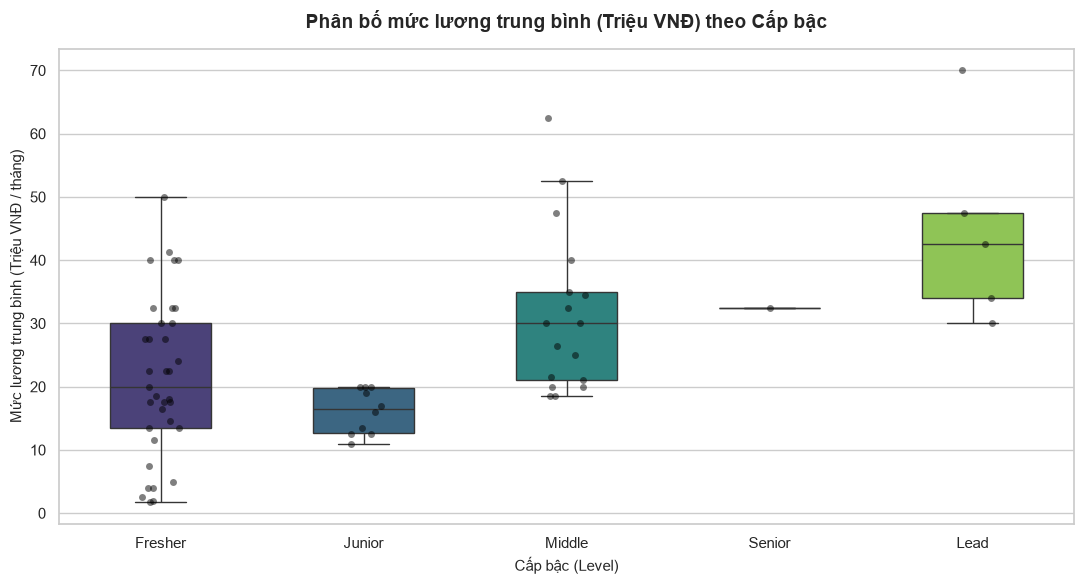

In [23]:
# 1. Phân bố mức lương theo từng cấp bậc
level_order = ['Fresher', 'Junior', 'Middle', 'Senior', 'Lead']
df_sal = df[~df['La_Thoa_Thuan'] & df['Luong_TB'].notna()].copy()

# Bảng thống kê mô tả mức lương theo cấp bậc
sal_stats = df_sal.groupby('Cap_Bac')['Luong_TB'].agg(['count', 'mean', 'median', 'min', 'max']).reindex(level_order).dropna(how='all')
print("=== THỐNG KÊ MỨC LƯƠNG TRUNG BÌNH (TRIỆU VNĐ) THEO CẤP BẬC ===")
display(sal_stats.round(2))

# Trực quan hóa Boxplot + Stripplot
plt.figure(figsize=(11, 6))
present_levels = [lvl for lvl in level_order if lvl in df_sal['Cap_Bac'].values]
sns.boxplot(data=df_sal, x='Cap_Bac', y='Luong_TB', order=present_levels, palette='viridis', width=0.5, showfliers=False)
sns.stripplot(data=df_sal, x='Cap_Bac', y='Luong_TB', order=present_levels, color='black', alpha=0.5, jitter=True, size=5)

plt.title('Phân bố mức lương trung bình (Triệu VNĐ) theo Cấp bậc', fontweight='bold', pad=15)
plt.xlabel('Cấp bậc (Level)')
plt.ylabel('Mức lương trung bình (Triệu VNĐ / tháng)')
plt.tight_layout()
plt.show()


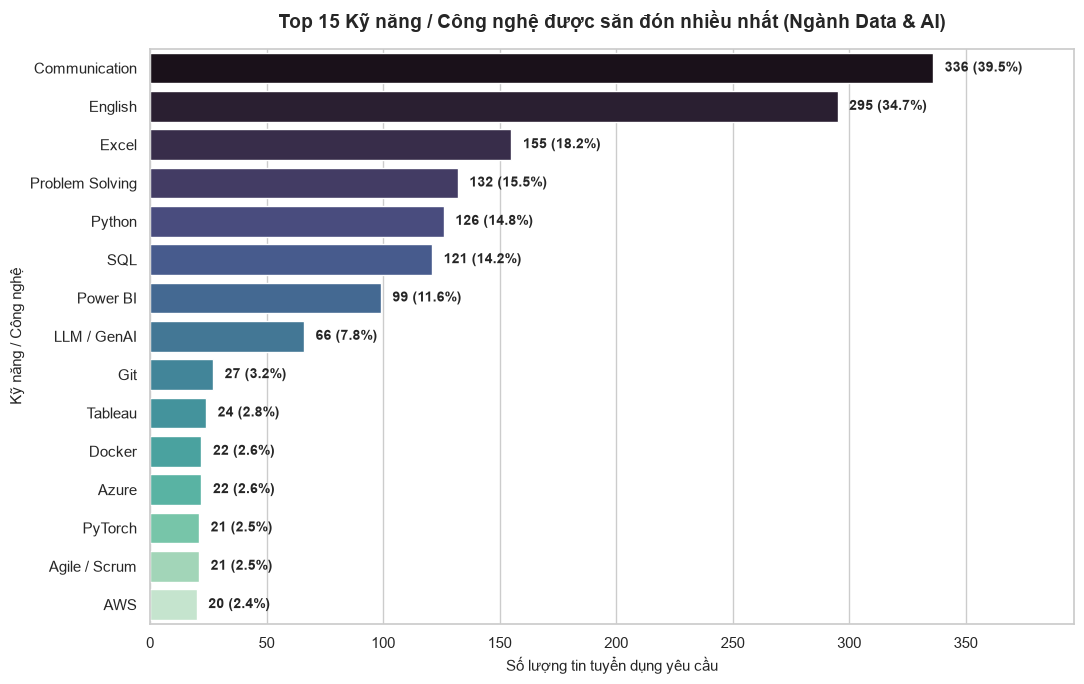

In [24]:
# 2. Top 15 kỹ năng/công nghệ được săn đón nhiều nhất
skill_counts = df[skill_cols].sum().sort_values(ascending=False).head(15)
skill_counts.index = [idx.replace('skill_', '') for idx in skill_counts.index]
skill_pct = (skill_counts / len(df) * 100).round(1)

plt.figure(figsize=(11, 7))
ax = sns.barplot(x=skill_counts.values, y=skill_counts.index, palette='mako')

for i, (count, pct) in enumerate(zip(skill_counts.values, skill_pct.values)):
    ax.text(count + 5, i, f'{count} ({pct}%)', va='center', fontsize=10, fontweight='bold')

plt.title('Top 15 Kỹ năng / Công nghệ được săn đón nhiều nhất (Ngành Data & AI)', fontweight='bold', pad=15)
plt.xlabel('Số lượng tin tuyển dụng yêu cầu')
plt.ylabel('Kỹ năng / Công nghệ')
plt.xlim(0, skill_counts.max() * 1.18)
plt.tight_layout()
plt.show()


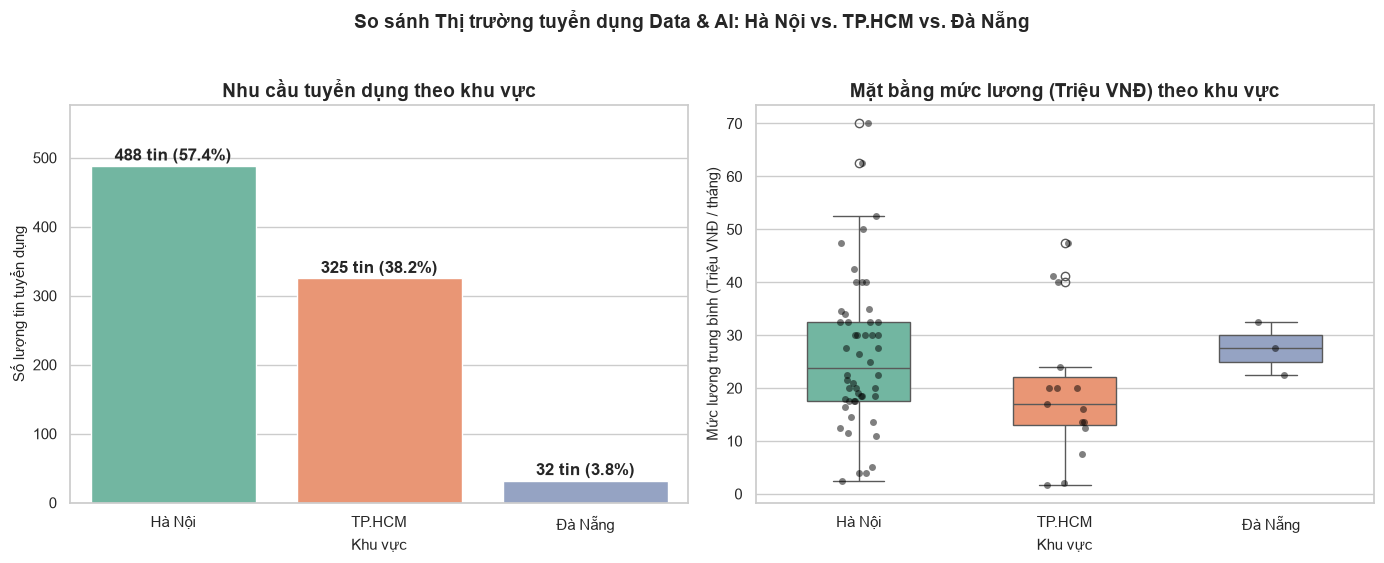

=== BẢNG TỔNG HỢP THEO KHU VỰC ===


,Tong_So_Tin,count,mean,median,min,max
Dia_Diem_Chuan,,,,,,
Hà Nội,488,50,26.45,23.75,2.50,70.0
TP.HCM,325,15,19.77,17.00,1.75,47.5
Đà Nẵng,32,3,27.50,27.50,22.50,32.5


In [25]:
# 3. So sánh nhu cầu tuyển dụng và mặt bằng lương giữa Hà Nội, TP.HCM và Đà Nẵng
regions = ['Hà Nội', 'TP.HCM', 'Đà Nẵng']
df_reg = df[df['Dia_Diem_Chuan'].isin(regions)]
df_reg_sal = df_sal[df_sal['Dia_Diem_Chuan'].isin(regions)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Biểu đồ trái: Số lượng tin tuyển dụng
reg_counts = df_reg['Dia_Diem_Chuan'].value_counts().reindex(regions).fillna(0)
sns.barplot(x=reg_counts.index, y=reg_counts.values, palette='Set2', ax=axes[0])
for i, v in enumerate(reg_counts.values):
    axes[0].text(i, v + 8, f'{int(v)} tin ({v/len(df)*100:.1f}%)', ha='center', fontweight='bold')
axes[0].set_title('Nhu cầu tuyển dụng theo khu vực', fontweight='bold')
axes[0].set_xlabel('Khu vực')
axes[0].set_ylabel('Số lượng tin tuyển dụng')
axes[0].set_ylim(0, reg_counts.max() * 1.18)

# Biểu đồ phải: Mặt bằng mức lương
sns.boxplot(data=df_reg_sal, x='Dia_Diem_Chuan', y='Luong_TB', order=regions, palette='Set2', ax=axes[1], width=0.5)
sns.stripplot(data=df_reg_sal, x='Dia_Diem_Chuan', y='Luong_TB', order=regions, color='black', alpha=0.5, ax=axes[1])
axes[1].set_title('Mặt bằng mức lương (Triệu VNĐ) theo khu vực', fontweight='bold')
axes[1].set_xlabel('Khu vực')
axes[1].set_ylabel('Mức lương trung bình (Triệu VNĐ / tháng)')

plt.suptitle('So sánh Thị trường tuyển dụng Data & AI: Hà Nội vs. TP.HCM vs. Đà Nẵng', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Bảng tổng hợp theo khu vực
print("=== BẢNG TỔNG HỢP THEO KHU VỰC ===")
reg_summary = df_reg_sal.groupby('Dia_Diem_Chuan')['Luong_TB'].agg(['count', 'mean', 'median', 'min', 'max']).reindex(regions)
reg_summary.insert(0, 'Tong_So_Tin', reg_counts)
display(reg_summary.round(2))
